# Arrival-weighted correction in a simulated IFCB mixture

This is a first-pass, end-to-end workflow that combines:

1. empirical arrival-distribution estimation from separate Alex and Jata IFCB directories;
2. latent mixture generation from those distributions;
3. fixed-inhibition IFCB sampling;
4. arrival-weighted-volume correction using the known reference distributions; and
5. paired error heat maps for uncorrected and corrected estimates.

The reference distributions are treated as the simulation's `b_true(t)` for this first experiment. This is intentionally an oracle-style test: the simulation is generated from the same distributions used for correction. It does not yet test uncertainty in estimating `b(t)`.

Existing notebooks and source data are not modified by this notebook.


## Decision checkpoint: reference data

Before running this notebook, confirm:

- the Alex and Jata directories contain merged IFCB CSV runs;
- each run contains `RunTime`, `InhibitTimeDiff`, and the appropriate classifier-score column;
- the classifier columns below are the columns to use for each target; and
- the reference runs are appropriate for defining arrival timing for the simulated populations.

If the two directories use different target-column names, update them independently below.


In [26]:
from pathlib import Path
import importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ---- User inputs ----
ALEX_REFERENCE_DIR = Path("/Users/michaelstaiger/Desktop/gitRepos/IFCBParticleSize/EmpyricalAnalysis/IFCBData/ResearchReport/Alex")
JATA_REFERENCE_DIR = Path("/Users/michaelstaiger/Desktop/gitRepos/IFCBParticleSize/EmpyricalAnalysis/IFCBData/ResearchReport/Jata")

ALEX_TARGET_COLUMN = "Alexandrium_catenella"
JATA_TARGET_COLUMN = "Jata"  # CHECKPOINT: replace with the actual Jata classifier column
CLASSIFIER_THRESHOLD = 0.9

RUN_DURATION_SECONDS = 1200.0
ANALYSIS_START_SECONDS = 0.0
BIN_WIDTH_SECONDS = 1.0
N_BINS = int((RUN_DURATION_SECONDS - ANALYSIS_START_SECONDS) / BIN_WIDTH_SECONDS)
SAMPLE_VOLUME_ML = 5.0
FLOW_SECONDS_PER_ML = 240.0
INHIBIT_TIME_SECONDS = 0.08

# Concentrations are particles/mL. The latent load is concentration * sample volume.
ALEX_CONCENTRATIONS = [100, 500, 1000, 1500, 2500, 3000, 3500]
JATA_CONCENTRATIONS = [100, 500, 1000, 1500, 2500, 3000, 3500]
N_REPLICATES = 10
BASE_SEED = 42

# Import the empirical-arrival implementation already present in this repository.
CORRECTION_SOURCE = Path("/Users/michaelstaiger/Desktop/gitRepos/IFCB-likelihood-correction/src/ifcb_arrival/empirical_arrival_distribution.py")
spec = importlib.util.spec_from_file_location("empirical_arrival_distribution", CORRECTION_SOURCE)
empirical_arrival = importlib.util.module_from_spec(spec)
spec.loader.exec_module(empirical_arrival)

estimate_empirical_b_from_directory = empirical_arrival.estimate_empirical_b_from_directory
_inactive_seconds_by_bin = empirical_arrival._inactive_seconds_by_bin

print(f"Using {N_BINS} bins of width {BIN_WIDTH_SECONDS:g} seconds")


Using 1200 bins of width 1 seconds


## 1. Estimate `b_true(t)` for Alex and Jata

The README estimator uses all rows to reconstruct availability and only rows above the target threshold to estimate target arrival intensity. The raw `b_t` column is retained here as the reference distribution for the oracle simulation.

The smoothed columns are available for later sensitivity analyses, but this first pass uses the unsmoothed `b_t`.


In [19]:
def estimate_reference_b(reference_dir, target_column):
    if not reference_dir.is_dir():
        raise FileNotFoundError(
            f"Reference directory does not exist: {reference_dir}. Update the input paths above."
        )
    return estimate_empirical_b_from_directory(
        reference_dir,
        target_column=target_column,
        classifier_threshold=CLASSIFIER_THRESHOLD,
        run_duration_seconds=RUN_DURATION_SECONDS,
        n_bins=N_BINS,
        runtime_column="RunTime",
        inhibition_duration_column="InhibitTimeDiff",
        analysis_start_seconds=ANALYSIS_START_SECONDS,
        support_smoothing_weight=0.0,
    )


b_alex = estimate_reference_b(ALEX_REFERENCE_DIR, ALEX_TARGET_COLUMN)
b_jata = estimate_reference_b(JATA_REFERENCE_DIR, JATA_TARGET_COLUMN)

assert np.isclose(b_alex["b_t"].sum(), 1.0)
assert np.isclose(b_jata["b_t"].sum(), 1.0)

print("Alex reference runs:", b_alex.attrs.get("n_runs"))
print("Jata reference runs:", b_jata.attrs.get("n_runs"))
print("Alex target detections:", b_alex.attrs.get("target_detection_count"))
print("Jata target detections:", b_jata.attrs.get("target_detection_count"))


Alex reference runs: 51
Jata reference runs: 54
Alex target detections: 443415
Jata target detections: 546060


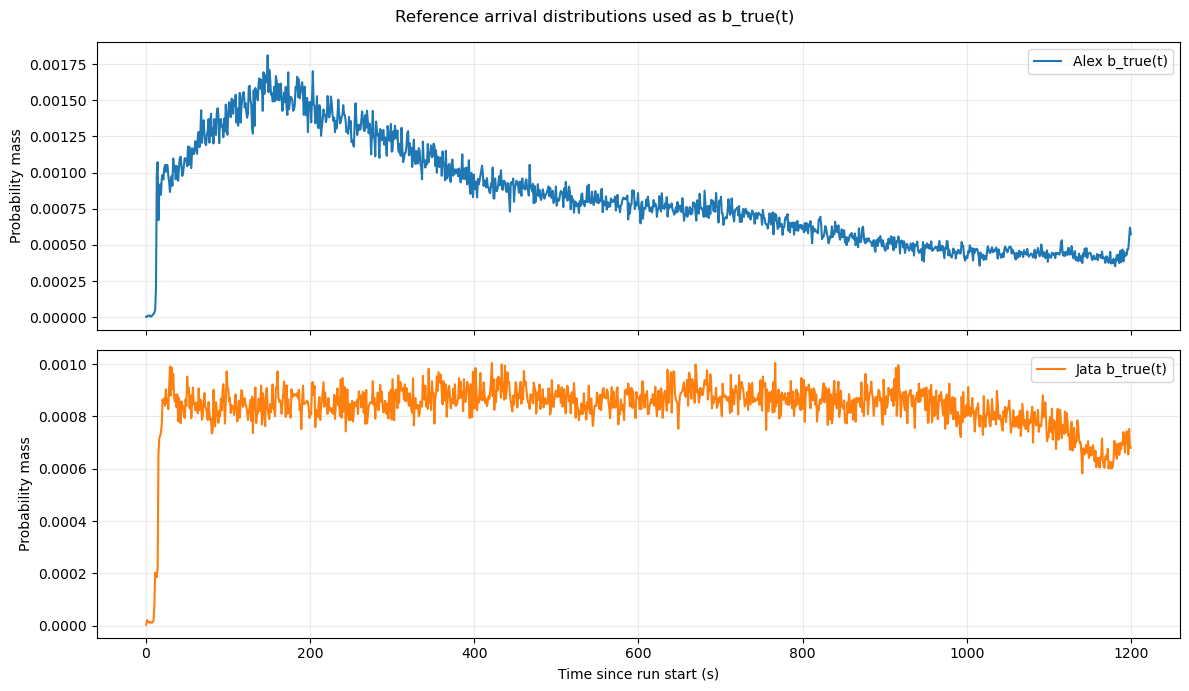

In [20]:
def plot_reference_distributions(b_alex, b_jata):
    fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
    axes[0].plot(b_alex["bin_center_seconds"], b_alex["b_t"], label="Alex b_true(t)")
    axes[1].plot(b_jata["bin_center_seconds"], b_jata["b_t"], color="tab:orange", label="Jata b_true(t)")
    for ax in axes:
        ax.grid(alpha=0.25)
        ax.legend()
        ax.set_ylabel("Probability mass")
    axes[1].set_xlabel("Time since run start (s)")
    fig.suptitle("Reference arrival distributions used as b_true(t)")
    plt.tight_layout()
    plt.show()


plot_reference_distributions(b_alex, b_jata)


## 2. Sample latent particles from `b_true(t)`

For this first pass, latent particle arrivals are sampled directly from the empirical bin probabilities. Uniform jitter within each bin prevents all particles from sharing the exact bin center.

This replaces the previous workflow's IPW-expanded arrival lists for this experiment. Those lists can be compared later, but using the distribution directly makes the simulated latent population explicit.


In [21]:
def sample_arrival_times_from_b(b_table, n_particles, rng):
    probabilities = b_table["b_t"].to_numpy(dtype=float)
    bin_starts = b_table["bin_start_seconds"].to_numpy(dtype=float)
    bin_ends = b_table["bin_end_seconds"].to_numpy(dtype=float)
    bin_indices = rng.choice(len(probabilities), size=int(n_particles), p=probabilities)
    return np.sort(rng.uniform(bin_starts[bin_indices], bin_ends[bin_indices]))


def make_mixture_from_b(b_alex, b_jata, alex_concentration, jata_concentration, scenario_id, seed):
    rng = np.random.default_rng(seed)
    n_alex = int(round(alex_concentration * SAMPLE_VOLUME_ML))
    n_jata = int(round(jata_concentration * SAMPLE_VOLUME_ML))
    alex_times = sample_arrival_times_from_b(b_alex, n_alex, rng)
    jata_times = sample_arrival_times_from_b(b_jata, n_jata, rng)

    alex_df = pd.DataFrame({
        "scenario_id": scenario_id,
        "Source_group": "Alexandrium",
        "arrival_time": alex_times,
    })
    jata_df = pd.DataFrame({
        "scenario_id": scenario_id,
        "Source_group": "Jata",
        "arrival_time": jata_times,
    })
    return pd.concat([alex_df, jata_df], ignore_index=True).sort_values("arrival_time").reset_index(drop=True)


## 3. Simulate inhibition and retain the availability history

The existing mixture notebook marks a particle as observed if it arrives after the previous inhibition interval. This version keeps the same logic but also returns the accepted-trigger intervals. Those intervals are needed to calculate the per-simulation availability vector `A_jt`.


In [22]:
def simulate_ifcb_sampling(input_df, inhibit_time=INHIBIT_TIME_SECONDS):
    ordered = input_df.sort_values("arrival_time").reset_index(drop=True).copy()
    arrival_times = ordered["arrival_time"].to_numpy(dtype=float)
    sampled = []
    accepted_times = []
    next_available_time = -np.inf

    for time in arrival_times:
        is_sampled = time >= next_available_time
        sampled.append(is_sampled)
        if is_sampled:
            accepted_times.append(time)
            next_available_time = time + inhibit_time

    ordered["sampled"] = sampled
    accepted_times = np.asarray(accepted_times, dtype=float)
    intervals = [(time, time + inhibit_time) for time in accepted_times]
    return ordered, intervals


def availability_from_intervals(intervals, n_bins=N_BINS):
    bin_edges = np.linspace(ANALYSIS_START_SECONDS, RUN_DURATION_SECONDS, n_bins + 1)
    bin_widths = np.diff(bin_edges)
    clipped = [
        (max(start, ANALYSIS_START_SECONDS), min(end, RUN_DURATION_SECONDS))
        for start, end in intervals
        if end > ANALYSIS_START_SECONDS and start < RUN_DURATION_SECONDS
    ]
    inactive_seconds = _inactive_seconds_by_bin(clipped, bin_edges)
    active_seconds = np.maximum(bin_widths - inactive_seconds, 0.0)
    return active_seconds / bin_widths


def arrival_weighted_fraction(b_table, active_fraction):
    b = b_table["b_t"].to_numpy(dtype=float)
    if len(b) != len(active_fraction):
        raise ValueError("b(t) and active_fraction must use the same time grid.")
    return float(np.dot(b, active_fraction))


## 4. Run the mixture simulation

For each scenario and replicate, this section stores:

- the known latent concentration;
- the observed target count after inhibition;
- the uncorrected estimate;
- the target-specific arrival-weighted fraction;
- the corrected estimate; and
- signed and absolute percentage errors.

The uncorrected estimate below follows the existing IFCB analysis: observed count divided by analyzed water volume. Analyzed volume is active run time divided by the 240 seconds/mL flow-rate convention.


In [27]:
def summarize_target(simulated_df, target_name, volume_analyzed_ml):
    target_mask = simulated_df["Source_group"].eq(target_name)
    latent_count = int(target_mask.sum())
    observed_count = int((target_mask & simulated_df["sampled"]).sum())
    true_concentration = latent_count / SAMPLE_VOLUME_ML
    active_volume_concentration = observed_count / volume_analyzed_ml
    return latent_count, observed_count, true_concentration, active_volume_concentration


def run_one_simulation(alex_concentration, jata_concentration, rep, b_alex, b_jata):
    scenario_id = f"Alex{alex_concentration}_Jata{jata_concentration}"
    seed = BASE_SEED + rep * 1_000_000 + int(alex_concentration) * 100 + int(jata_concentration)
    mixture = make_mixture_from_b(
        b_alex, b_jata, alex_concentration, jata_concentration, scenario_id, seed
    )
    sampled, intervals = simulate_ifcb_sampling(mixture)
    active_fraction = availability_from_intervals(intervals)
    bin_widths = np.diff(
        np.linspace(ANALYSIS_START_SECONDS, RUN_DURATION_SECONDS, N_BINS + 1)
    )
    active_seconds = float(np.sum(active_fraction * bin_widths))
    volume_analyzed_ml = active_seconds / FLOW_SECONDS_PER_ML
    if volume_analyzed_ml <= 0:
        raise ValueError("Simulation produced zero analyzed volume.")
    alex_fraction = arrival_weighted_fraction(b_alex, active_fraction)
    jata_fraction = arrival_weighted_fraction(b_jata, active_fraction)

    records = []
    for target_name, target_b, target_fraction in [
        ("Alexandrium", b_alex, alex_fraction),
        ("Jata", b_jata, jata_fraction),
    ]:
        latent_count, observed_count, true_concentration, active_volume_concentration = summarize_target(
            sampled, target_name, volume_analyzed_ml
        )
        corrected_concentration = (
            observed_count / (SAMPLE_VOLUME_ML * target_fraction)
            if target_fraction > 0
            else np.nan
        )
        error_naive = (
            100 * (active_volume_concentration - true_concentration) / true_concentration
            if true_concentration > 0
            else np.nan
        )
        error_corrected = (
            100 * (corrected_concentration - true_concentration) / true_concentration
            if true_concentration > 0 and np.isfinite(corrected_concentration)
            else np.nan
        )
        records.append({
            "rep": rep,
            "scenario_id": scenario_id,
            "alex_concentration_requested": alex_concentration,
            "jata_concentration_requested": jata_concentration,
            "target": target_name,
            "latent_count": latent_count,
            "observed_count": observed_count,
            "true_concentration": true_concentration,
            "active_seconds": active_seconds,
            "volume_analyzed_ml": volume_analyzed_ml,
            "active_volume_concentration": active_volume_concentration,
            "arrival_weighted_fraction": target_fraction,
            "corrected_concentration": corrected_concentration,
            "active_volume_error_percent": error_naive,
            "corrected_error_percent": error_corrected,
            "absolute_active_volume_error_percent": abs(error_naive) if np.isfinite(error_naive) else np.nan,
            "absolute_corrected_error_percent": abs(error_corrected) if np.isfinite(error_corrected) else np.nan,
        })
    return records


results = []
for rep in range(1, N_REPLICATES + 1):
    for alex_concentration in ALEX_CONCENTRATIONS:
        for jata_concentration in JATA_CONCENTRATIONS:
            results.extend(
                run_one_simulation(
                    alex_concentration, jata_concentration, rep, b_alex, b_jata
                )
            )

results_df = pd.DataFrame(results)
results_df.head()


,rep,scenario_id,alex_concentration_requested,jata_concentration_requested,target,latent_count,observed_count,true_concentration,active_seconds,volume_analyzed_ml,active_volume_concentration,arrival_weighted_fraction,corrected_concentration,active_volume_error_percent,corrected_error_percent,absolute_active_volume_error_percent,absolute_corrected_error_percent
0,1,Alex100_Jata100,100,100,Alexandrium,500,468,100.0,1124.720000,4.686333,99.864855,0.932204,100.407194,-0.135145,0.407194,0.135145,0.407194
1,1,Alex100_Jata100,100,100,Jata,500,473,100.0,1124.720000,4.686333,100.931787,0.936332,101.032531,0.931787,1.032531,0.931787,1.032531
2,1,Alex100_Jata500,100,500,Alexandrium,500,422,100.0,1000.640000,4.169333,101.215222,0.826310,102.140877,1.215222,2.140877,1.215222,2.140877
3,1,Alex100_Jata500,100,500,Jata,2500,2070,500.0,1000.640000,4.169333,496.482251,0.830980,498.206660,-0.703550,-0.358668,0.703550,0.358668
4,1,Alex100_Jata1000,100,1000,Alexandrium,500,357,100.0,880.906612,3.670444,97.263432,0.726573,98.269531,-2.736568,-1.730469,2.736568,1.730469


## 5. Aggregate replicates

The heat maps use the mean signed percentage error across replicates. The absolute-error summaries are retained because the largest positive and negative biases can otherwise cancel.


In [28]:
summary_df = (
    results_df
    .groupby(["target", "alex_concentration_requested", "jata_concentration_requested"], as_index=False)
    .agg(
        mean_active_volume_error_percent=("active_volume_error_percent", "mean"),
        mean_corrected_error_percent=("corrected_error_percent", "mean"),
        mean_absolute_active_volume_error_percent=("absolute_active_volume_error_percent", "mean"),
        mean_absolute_corrected_error_percent=("absolute_corrected_error_percent", "mean"),
        sd_active_volume_error_percent=("active_volume_error_percent", "std"),
        sd_corrected_error_percent=("corrected_error_percent", "std"),
    )
)
summary_df.head()


,target,alex_concentration_requested,jata_concentration_requested,mean_active_volume_error_percent,mean_corrected_error_percent,mean_absolute_active_volume_error_percent,mean_absolute_corrected_error_percent,sd_active_volume_error_percent,sd_corrected_error_percent
0,Alexandrium,100,100,-0.934309,-0.296858,0.999770,0.708549,1.066027,1.105721
1,Alexandrium,100,500,0.335966,1.226348,1.291931,1.656174,1.757929,1.729115
2,Alexandrium,100,1000,-0.330939,0.761046,2.101656,2.038282,2.494326,2.486618
3,Alexandrium,100,1500,-0.981733,0.255249,3.018100,3.036345,3.504607,3.531717
4,Alexandrium,100,2500,-0.950963,0.756583,3.078708,3.081301,3.880399,3.867615


## 6. Produce the two heat-map sets

Each target gets one uncorrected and one corrected heat map. Color limits are shared within each target so the change is visually comparable.


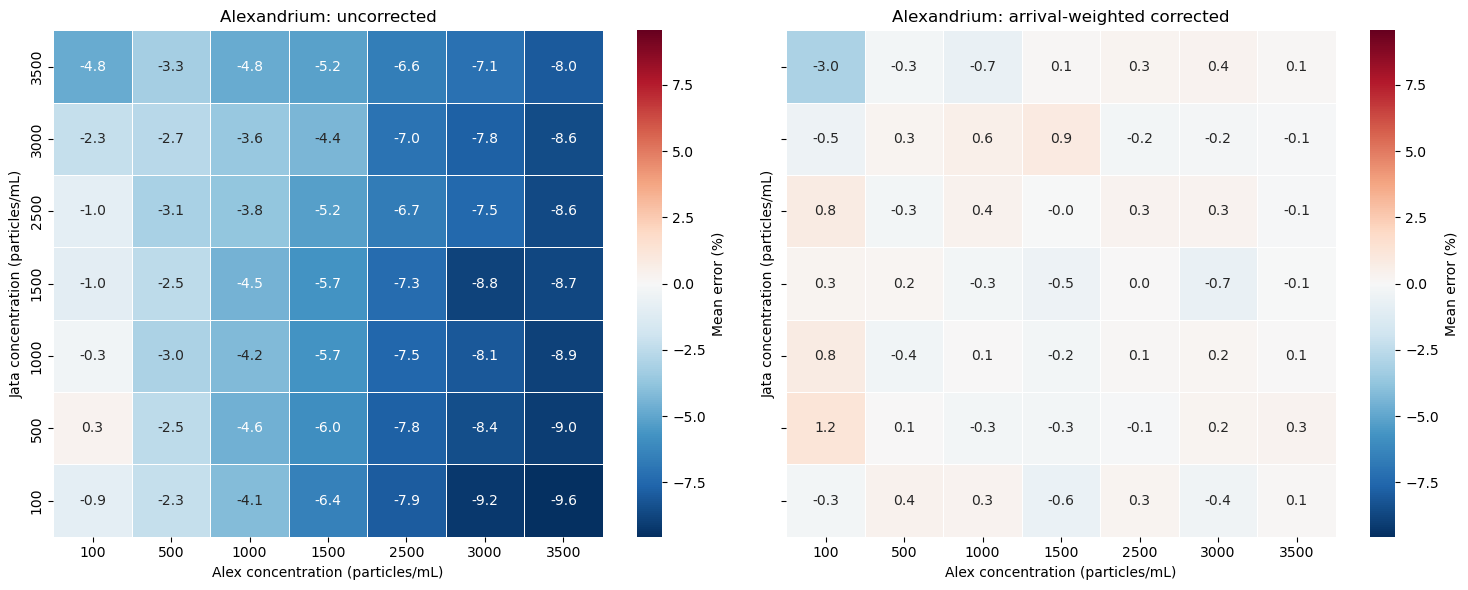

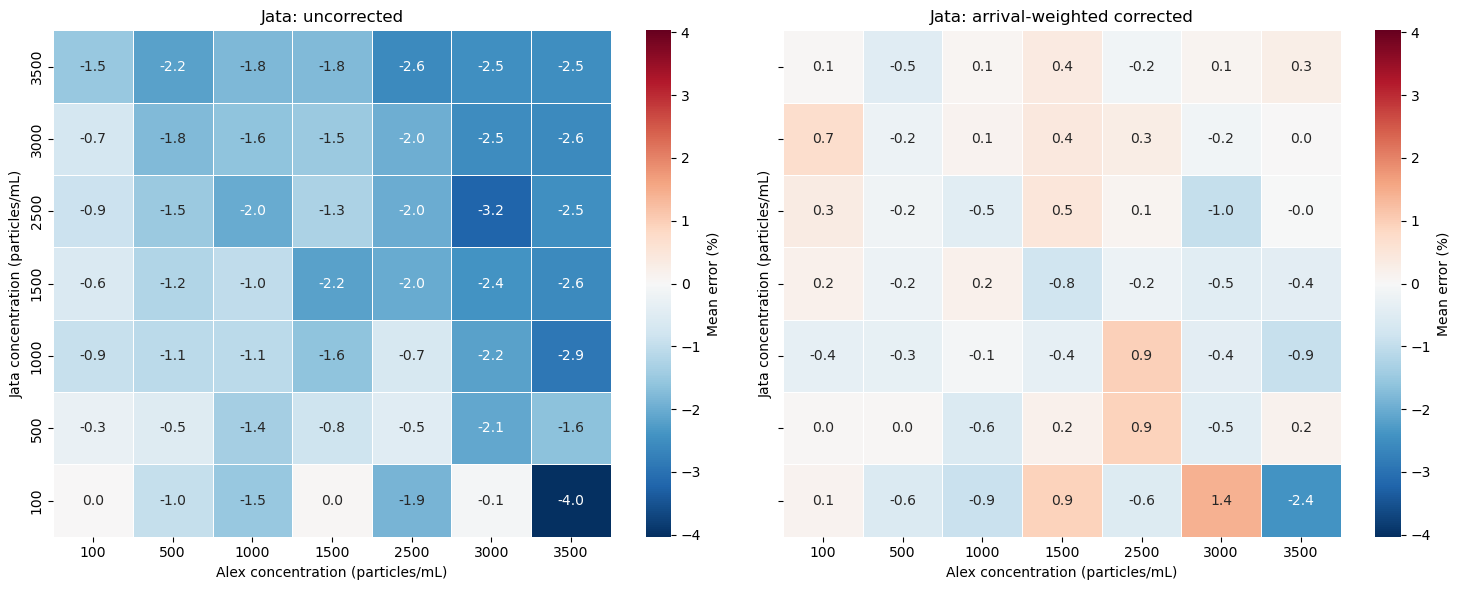

In [30]:
def heatmap_matrix(summary, target, value_column):
    subset = summary[summary["target"] == target]
    return subset.pivot(
        index="jata_concentration_requested",
        columns="alex_concentration_requested",
        values=value_column,
    ).sort_index(ascending=False)


def plot_error_pair(summary, target):
    naive = heatmap_matrix(summary, target, "mean_active_volume_error_percent")
    corrected = heatmap_matrix(summary, target, "mean_corrected_error_percent")
    limit = np.nanmax(np.abs([naive.to_numpy(), corrected.to_numpy()]))

    fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
    for ax, matrix, title in [
        (axes[0], naive, f"{target}: uncorrected"),
        (axes[1], corrected, f"{target}: arrival-weighted corrected"),
    ]:
        sns.heatmap(
            matrix, ax=ax, cmap="RdBu_r", center=0, vmin=-limit, vmax=limit,
            annot=True, fmt=".1f", linewidths=0.5, linecolor="white",
            cbar_kws={"label": "Mean error (%)"},
        )
        ax.set_title(title)
        ax.set_xlabel("Alex concentration (particles/mL)")
        ax.set_ylabel("Jata concentration (particles/mL)")
    plt.tight_layout()
    plt.show()


plot_error_pair(summary_df, "Alexandrium")
plot_error_pair(summary_df, "Jata")


In [ ]:
def plot_absolute_error_improvement(summary, target):
    subset = summary[summary["target"] == target].copy()
    subset["absolute_error_improvement"] = (
        subset["mean_absolute_active_volume_error_percent"]
        - subset["mean_absolute_corrected_error_percent"]
    )
    matrix = subset.pivot(
        index="jata_concentration_requested",
        columns="alex_concentration_requested",
        values="absolute_error_improvement",
    ).sort_index(ascending=False)
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        matrix, cmap="RdYlGn", center=0, annot=True, fmt=".1f",
        linewidths=0.5, linecolor="white",
        cbar_kws={"label": "Absolute-error reduction (percentage points)"},
    )
    plt.title(f"{target}: improvement from arrival-weighted correction")
    plt.xlabel("Requested Alex concentration (particles/mL)")
    plt.ylabel("Requested Jata concentration (particles/mL)")
    plt.tight_layout()
    plt.show()


# Optional diagnostic: positive values mean the correction reduced absolute error.
plot_absolute_error_improvement(summary_df, "Alexandrium")
plot_absolute_error_improvement(summary_df, "Jata")


## Checkpoints before interpreting results

1. **Target columns:** confirm the Jata classifier column and whether the Alex/Jata columns are scores or binary labels.
2. **Reference runs:** confirm that the Alex and Jata directories are independent reference runs and are scientifically appropriate for defining the simulated arrival shapes.
3. **Time origin:** confirm that `RunTime` is aligned to a common run start and that the same 0–1200 second window is appropriate for both targets.
4. **Volume convention:** this first pass uses the known 5 mL nominal volume for both the true and naive estimates. The original mixture notebook's time-derived volume can be added as a separate baseline after its units and interpretation are confirmed.
5. **Simulation interpretation:** because the simulation samples from the same estimated `b(t)` used in the correction, corrected performance here tests the mechanics of the correction. It does not yet measure the impact of uncertainty or mismatch in `b(t)`.

The next validation step should use one set of reference runs to construct `b(t)` and a separate arrival-generating process or held-out reference set for evaluation.
